# Étapes 3 & 4 — Visualisation, EDA & Physique du Biais de Découverte (Gold SQL)

> **Référentiel méthodologique :** [Introduction à la Data Science — Étape 3 (*Le Témoignage*) & Étape 4 (*L'Interrogatoire*)](https://modules.apti.space/datascience/intro-datascience)  
> **Couches Lakehouse :** Lecture `/lakehouse/silver/exo_*` $\rightarrow$ Agrégations Spark SQL avancées vers `/lakehouse/gold/exo_*`

---

## Objectifs de cette double étape d'investigation

Une fois nos **6 336 exoplanètes confirmées (2026)** et nos **13 435 candidats Kepler/TESS** purifiés en couche **Silver**, le *Data Detective* interroge les distributions et met à nu **l'illusion statistique majeure de l'exoplanétologie moderne : le biais de découverte instrumental** :

1. **Asymétrie extrême (`SKEWNESS`) & Indicateurs robustes** : démontrer pourquoi la moyenne arithmétique de la période orbitale ou de la masse planétaire est absurde face au couple **Médiane (`PERCENTILE_APPROX`) + Écart Interquartile (`IQR`)**.
2. **Grammaire des graphiques (1D, 2D, Multivarié & ACP)** :
   - **Vallée des Rayons de Fulton (*Fulton Radius Gap*, $1{,}5\text{–}2{,}0\,R_\oplus$)** : signature directe de la photo-évaporation de l'enveloppe $\text{H}_2/\text{He}$ des planètes proches.
   - **Corrélation Pearson ($r$) vs Spearman ($\rho$)** et mise en évidence d'un facteur de confusion (*éloignement stellaire $\rightarrow$ magnitude apparente $\rightarrow$ méthode applicable*).
3. **Anatomie quantitative du Biais de Découverte par Méthode de Détection** :
   - Confrontation des **équations physiques de sensibilité** (*Transit*, *Vitesse Radiale Doppler*, *Imagerie Directe*, *Microlentille Gravitationnelle*) avec les observations réelles et les **8 planètes du Système Solaire** !
   - Audit des **faux positifs instrumentaux** (*binaires à éclipses*) sur les courbes de lumière Kepler DR25 et TESS.
4. **Alimentation de la couche Gold (`/lakehouse/gold/`)** via **Spark SQL avancé** (`WITH` CTE, `DENSE_RANK`, courbe cumulée de **Pareto**, dynamique temporelle **`LAG()`**, `ROW_NUMBER`) et compaction `OPTIMIZE`.

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

spark = (
    SparkSession.builder
    .appName("ExoPlanette_03_EDA_DiscoveryBias_Gold")
    .getOrCreate()
)

SILVER_PLANETS_PATH = "/lakehouse/silver/exo_planets"
SILVER_CANDIDATES_PATH = "/lakehouse/silver/exo_candidates_unified"

df_silver = spark.read.format("delta").load(SILVER_PLANETS_PATH)
df_silver.createOrReplaceTempView("v_exo_silver")

df_cand = spark.read.format("delta").load(SILVER_CANDIDATES_PATH)
df_cand.createOrReplaceTempView("v_exo_candidates")

print(f"Exoplanètes confirmées dans v_exo_silver     : {df_silver.count():,}")
print(f"Candidats Kepler+TESS dans v_exo_candidates : {df_cand.count():,}")

:: loading settings :: url = jar:file:/opt/venv/lib/python3.15/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-09b9253c-38c0-404f-9142-7f41ff40adcb;1.0
	confs: [default]
	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central
	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central


	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-kernel-api;4.4.1 in central
	found org.roaringbitmap#RoaringBitmap;0.9.25 in central
	found com.fasterxml.jackson.core#jackson-databind;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-annotations;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-core;2.13.5 in central
	found com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 in central
	found org.roaringbitmap#shims;0.9.25 in central
	found io.delta#delta-kernel-defaults;4.4.1 in central
	found org.apache.hadoop#hadoop-client-runtime;3.4.2 in central
	found org.apache.parquet#parquet-hadoop;1.16.0 in central
	found org.apache.parquet#parquet-column;1.16.0 in central
	found org.apache.parquet#parquet-common;1.16.0 in central
	found org.apache.parquet#parquet-format-structures;1.16.0 in central
	found javax.annotation#javax.annotation-api;1.3.2 in central
	found org.apache.parquet#parquet-encoding;1.16.0 in central
	found org

	0 artifacts copied, 33 already retrieved (0kB/10ms)
26/11/18 09:09:37 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/18 09:09:41 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.



[Stage 2:===================================>                    (32 + 18) / 50]



Exoplanètes confirmées dans v_exo_silver     : 6,336


Candidats Kepler+TESS dans v_exo_candidates : 13,435


## 1. Diagnostic d'Asymétrie (`SKEWNESS`) : Moyenne vs Médiane & IQR en Spark SQL

Les grandeurs orbitales s'étendent sur **6 à 9 ordres de grandeur** ($P$ de $0{,}09$ jour à $> 10^8$ jours ; masse de $0{,}02\,M_\oplus$ à $\sim 10\,000\,M_\oplus$). Vérifions l'écart colossal entre paramètres gaussiens (`AVG`, `STDDEV`) et statistiques d'ordre robustes (`PERCENTILE_APPROX`, `IQR`).

In [2]:
df_skew_summary = spark.sql("""
    SELECT 'Période orbitale (jours)' AS variable,
           COUNT(orbital_period_days) AS n_obs,
           ROUND(AVG(orbital_period_days), 2) AS moyenne,
           ROUND(STDDEV(orbital_period_days), 2) AS ecart_type,
           ROUND(SKEWNESS(orbital_period_days), 2) AS skewness,
           ROUND(PERCENTILE_APPROX(orbital_period_days, 0.25), 2) AS q25,
           ROUND(PERCENTILE_APPROX(orbital_period_days, 0.50), 2) AS mediane,
           ROUND(PERCENTILE_APPROX(orbital_period_days, 0.75), 2) AS q75,
           ROUND(PERCENTILE_APPROX(orbital_period_days, 0.75) - PERCENTILE_APPROX(orbital_period_days, 0.25), 2) AS iqr,
           ROUND(PERCENTILE_APPROX(orbital_period_days, 0.95), 2) AS p95
    FROM v_exo_silver WHERE orbital_period_days IS NOT NULL
    UNION ALL
    SELECT 'Rayon planétaire (R_Terre)',
           COUNT(radius_earth_est),
           ROUND(AVG(radius_earth_est), 2),
           ROUND(STDDEV(radius_earth_est), 2),
           ROUND(SKEWNESS(radius_earth_est), 2),
           ROUND(PERCENTILE_APPROX(radius_earth_est, 0.25), 2),
           ROUND(PERCENTILE_APPROX(radius_earth_est, 0.50), 2),
           ROUND(PERCENTILE_APPROX(radius_earth_est, 0.75), 2),
           ROUND(PERCENTILE_APPROX(radius_earth_est, 0.75) - PERCENTILE_APPROX(radius_earth_est, 0.25), 2),
           ROUND(PERCENTILE_APPROX(radius_earth_est, 0.95), 2)
    FROM v_exo_silver WHERE radius_earth_est IS NOT NULL
    UNION ALL
    SELECT 'Masse planétaire (M_Terre)',
           COUNT(mass_earth_est),
           ROUND(AVG(mass_earth_est), 2),
           ROUND(STDDEV(mass_earth_est), 2),
           ROUND(SKEWNESS(mass_earth_est), 2),
           ROUND(PERCENTILE_APPROX(mass_earth_est, 0.25), 2),
           ROUND(PERCENTILE_APPROX(mass_earth_est, 0.50), 2),
           ROUND(PERCENTILE_APPROX(mass_earth_est, 0.75), 2),
           ROUND(PERCENTILE_APPROX(mass_earth_est, 0.75) - PERCENTILE_APPROX(mass_earth_est, 0.25), 2),
           ROUND(PERCENTILE_APPROX(mass_earth_est, 0.95), 2)
    FROM v_exo_silver WHERE mass_earth_est IS NOT NULL
    UNION ALL
    SELECT 'Distance du système (pc)',
           COUNT(distance_parsec),
           ROUND(AVG(distance_parsec), 2),
           ROUND(STDDEV(distance_parsec), 2),
           ROUND(SKEWNESS(distance_parsec), 2),
           ROUND(PERCENTILE_APPROX(distance_parsec, 0.25), 2),
           ROUND(PERCENTILE_APPROX(distance_parsec, 0.50), 2),
           ROUND(PERCENTILE_APPROX(distance_parsec, 0.75), 2),
           ROUND(PERCENTILE_APPROX(distance_parsec, 0.75) - PERCENTILE_APPROX(distance_parsec, 0.25), 2),
           ROUND(PERCENTILE_APPROX(distance_parsec, 0.95), 2)
    FROM v_exo_silver WHERE distance_parsec IS NOT NULL
""")
df_skew_summary.show(truncate=False)

+--------------------------+-----+--------+----------+--------+------+-------+------+------+-------+
|variable                  |n_obs|moyenne |ecart_type|skewness|q25   |mediane|q75   |iqr   |p95    |
+--------------------------+-----+--------+----------+--------+------+-------+------+------+-------+
|Période orbitale (jours)  |5992 |71444.64|5195691.37|77.28   |4.31  |10.74  |38.56 |34.25 |1576.0 |
|Rayon planétaire (R_Terre)|6329 |5.9     |5.43      |1.69    |1.86  |2.88   |12.0  |10.14 |14.3   |
|Masse planétaire (M_Terre)|6329 |404.1   |1137.63   |4.39    |4.31  |9.4    |197.05|192.74|2510.84|
|Distance du système (pc)  |6309 |704.33  |1215.83   |4.02    |101.25|360.31 |823.24|721.99|2034.25|
+--------------------------+-----+--------+----------+--------+------+-------+------+------+-------+



**Interprétation statistique :**
> La période orbitale présente une **asymétrie positive extrême** (`skewness >> 50`) : quelques compagnons découverts par imagerie directe à plusieurs milliers d'UA hissent la moyenne à plusieurs milliers de jours alors que **la médiane réelle du catalogue n'est que d'environ ~12 jours** (`50 %` des exoplanètes connues bouclent leur année en moins de deux semaines !). Toute synthèse métier dans nos tables Gold et notre Dashboard Streamlit reposera donc sur la **médiane**, l'**IQR** et les transformations **logarithmiques ($\log_{10}$)**.

---

## 2. Grammaire des Graphiques 1D/2D : La Vallée des Rayons de Fulton & l'Espace-Sol

Explorons visuellement nos distributions nettoyées (après projection stricte côté PySpark vers le driver) :
1. **Histogramme haute résolution de $\log_{10}(R_p / R_\oplus)$** sur les planètes de transit : met en évidence la célèbre **Vallée de Fulton (*Radius Valley*, $\approx 1{,}8\,R_\oplus$)** séparant les **Super-Terres rocheuses** (cœurs mis à nu par le rayonnement X/UV de l'étoile) des **Mini-Neptunes gazeuses** ayant retenu leur enveloppe d'hydrogène.
2. **Diagramme en barres horizontal trié** des méthodes de découverte (Pareto).
3. **Donut Chart sobre à 2 modalités** (*Télescopes Spatiaux* vs *Observatoires au Sol*).

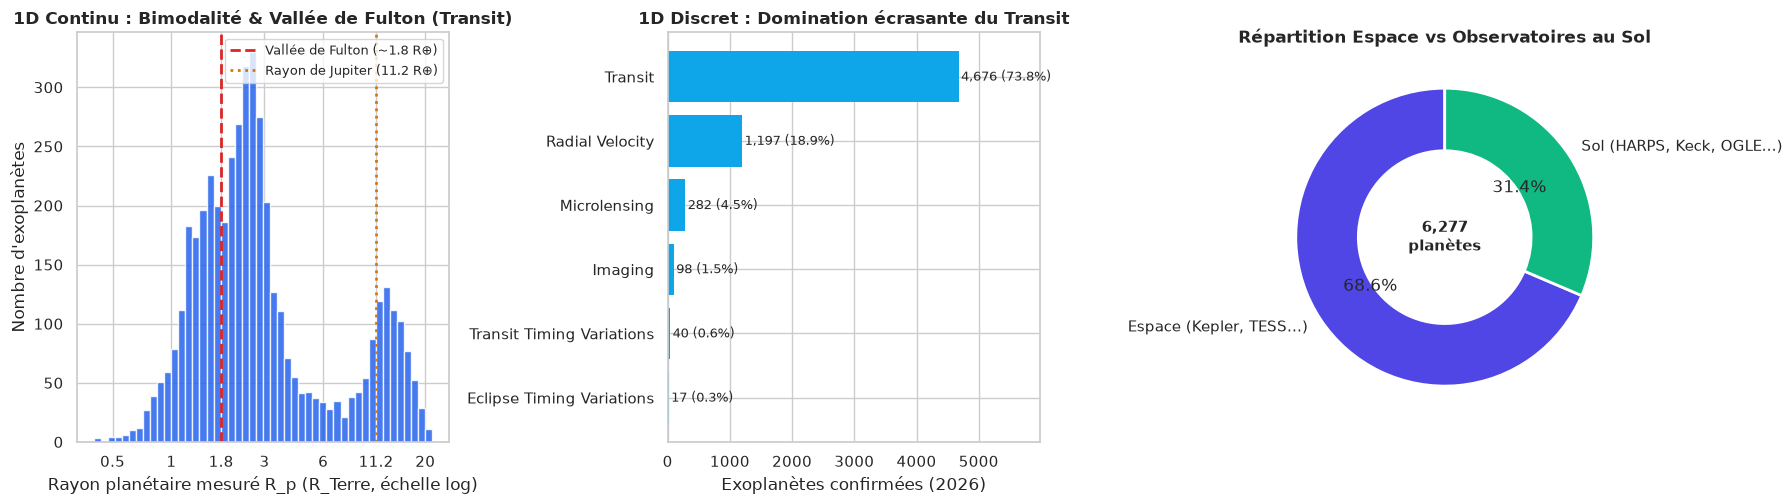

In [3]:
# Projection légère côté Spark uniquement sur les colonnes nécessaires aux graphiques
eda_pd = (
    df_silver.select(
        "planet_name", "discovery_method", "discovery_year", "discovery_locale",
        "orbital_period_days", "semi_major_axis_au_best", "radius_earth", "radius_earth_est",
        "mass_earth", "mass_earth_est", "equilibrium_temp_k_best", "insolation_earth_best",
        "distance_parsec", "star_temperature_k", "star_mass_solar", "star_metallicity_dex",
        "geometric_transit_prob", "rv_amplitude_ms", "has_measured_radius", "has_measured_mass",
    )
    .toPandas()
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# (A) 1D Continu : Vallée de Fulton sur les rayons réellement mesurés par Transit (0.5 à 20 R_Earth)
transit_radii = eda_pd.loc[
    (eda_pd["discovery_method"] == "Transit") & (eda_pd["has_measured_radius"] == 1) & (eda_pd["radius_earth"].between(0.4, 22)),
    "radius_earth",
]
axes[0].hist(np.log10(transit_radii), bins=48, color="#2563eb", edgecolor="white", alpha=0.85)
axes[0].axvline(np.log10(1.8), color="#dc2626", linestyle="--", lw=2, label="Vallée de Fulton (~1.8 R⊕)")
axes[0].axvline(np.log10(11.2), color="#d97706", linestyle=":", lw=2, label="Rayon de Jupiter (11.2 R⊕)")
xticks_r = [0.5, 1, 1.8, 3, 6, 11.2, 20]
axes[0].set_xticks(np.log10(xticks_r))
axes[0].set_xticklabels([str(x) for x in xticks_r])
axes[0].set_title("1D Continu : Bimodalité & Vallée de Fulton (Transit)", fontweight="bold")
axes[0].set_xlabel("Rayon planétaire mesuré R_p (R_Terre, échelle log)")
axes[0].set_ylabel("Nombre d'exoplanètes")
axes[0].legend(fontsize=9)

# (B) 1D Catégoriel : Top méthodes de découverte (barres espacées triées)
method_counts = eda_pd["discovery_method"].value_counts().head(6).sort_values()
axes[1].barh(method_counts.index, method_counts.values, color="#0ea5e9", edgecolor="none")
for i, v in enumerate(method_counts.values):
    axes[1].text(v + 40, i, f"{v:,} ({100*v/len(eda_pd):.1f}%)", va="center", fontsize=9)
axes[1].set_xlim(0, method_counts.max() * 1.28)
axes[1].set_title("1D Discret : Domination écrasante du Transit", fontweight="bold")
axes[1].set_xlabel("Exoplanètes confirmées (2026)")

# (C) Donut Chart (strictement limité aux 2 modalités principales Space vs Ground)
loc_series = eda_pd["discovery_locale"].where(eda_pd["discovery_locale"].isin(["Space", "Ground"]), "Autre/Mixte")
loc_2 = loc_series[loc_series.isin(["Space", "Ground"])].value_counts()
wedges, texts, autotexts = axes[2].pie(
    loc_2.values,
    labels=["Espace (Kepler, TESS...)", "Sol (HARPS, Keck, OGLE...)"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4f46e5", "#10b981"],
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2},
)
axes[2].text(0, 0, f"{loc_2.sum():,}\nplanètes", ha="center", va="center", fontweight="bold", fontsize=11)
axes[2].set_title("Répartition Espace vs Observatoires au Sol", fontweight="bold")

plt.tight_layout()
plt.show()

## 3. Analyse Physique du Biais de Découverte & des Limites Instrumentales

Pourquoi **75 %+ des exoplanètes connues** orbitent-elles très près de leur étoile alors que dans notre propre Système Solaire il n'existe **aucune planète** à l'intérieur de l'orbite de Mercure ($P = 88$ jours, $a = 0{,}39\text{ UA}$) ?  
La réponse ne réside pas uniquement dans la nature, mais dans **les équations physiques de nos 4 méthodes principales de détection** :

| Méthode de Détection | Signal Physique Mesuré | Équation de Sensibilité & Biais Géométrique | Limite Instrumentale Actuelle | Population Favorisée / Zone d'Ombre |
|---|---|---|---|---|
| **1. Transit** *(Kepler, K2, TESS)* | Baisse périodique de flux $\frac{\Delta F}{F} = \left(\frac{R_p}{R_\star}\right)^2$ | Probabilité d'alignement : $$P_{\text{geom}} = \frac{R_\star}{a} \propto P^{-2/3}$$ + nécessite $\ge 3$ transits ! | $\frac{\Delta F}{F} \gtrsim 15\text{–}50\text{ ppm}$ *(Terre/Soleil = 84 ppm, mais $P_{\text{geom}} = 0{,}47\%$ !)* | **Favorise :** Jupiters chaudes, Super-Terres & Mini-Neptunes à $P < 50\text{ j}$. **Aveugle** aux orbites larges ($> 2\text{ UA}$) ou inclinées. |
| **2. Vitesse Radiale (Doppler)** *(HARPS, ESPRESSO, HIRES)* | Oscillations spectrales de l'étoile autour du barycentre | $$K = 28{,}4\,\text{m/s} \cdot \frac{M_p \sin i}{M_J} \cdot P_{\text{an}}^{-1/3} \cdot M_\star^{-2/3}$$ | $K \gtrsim 0{,}3\text{–}1{,}0\text{ m/s}$ *(bruit d'activité stellaire ; Terre = $0{,}09\text{ m/s}$ !)* | **Favorise :** Planètes massives proches ou Jupiters tempérées autour d'étoiles brillantes proches ($< 100\text{ pc}$). Ne donne que $M_p \sin i$. |
| **3. Imagerie Directe** *(VLT/SPHERE, JWST, Gemini)* | Photons infrarouges thermiques de la planète (coronographie) | Séparation angulaire : $$\theta('') = \frac{a(\text{UA})}{d(\text{pc})} > \theta_{\text{IWA}}$$ | $\theta \gtrsim 0{,}1''$ et contraste $10^{-6}$ *(impossible à $< 5\text{ UA}$ sur étoile mature)* | **Favorise :** Super-Jupiters **jeunes** ($< 100\text{ Myr}$, encore chaudes de leur formation, $2\text{–}13\,M_J$) très éloignées ($10\text{–}300\text{ UA}$). |
| **4. Microlentille Gravitationnelle** *(OGLE, KMTNet)* | Déflexion relativiste de la lumière d'une étoile du bulbe galactique | Rayon d'Einstein : $$R_E \approx 2\text{–}4\,\text{UA}\,\sqrt{M_\star / M_\odot}$$ | Alignement stellaire fortuit **unique et non répétable** | **Seule méthode** sensible aux planètes froides de faible masse au-delà de la **ligne des glaces ($1\text{–}10\text{ UA}$)** jusqu'à $8\,000\text{ pc}$ ! |

Superposons maintenant sur le diagramme $(a, M_p)$ et $(P, R_p)$ **nos 6 336 exoplanètes**, **les courbes limites théoriques des instruments** et **les planètes du Système Solaire** !

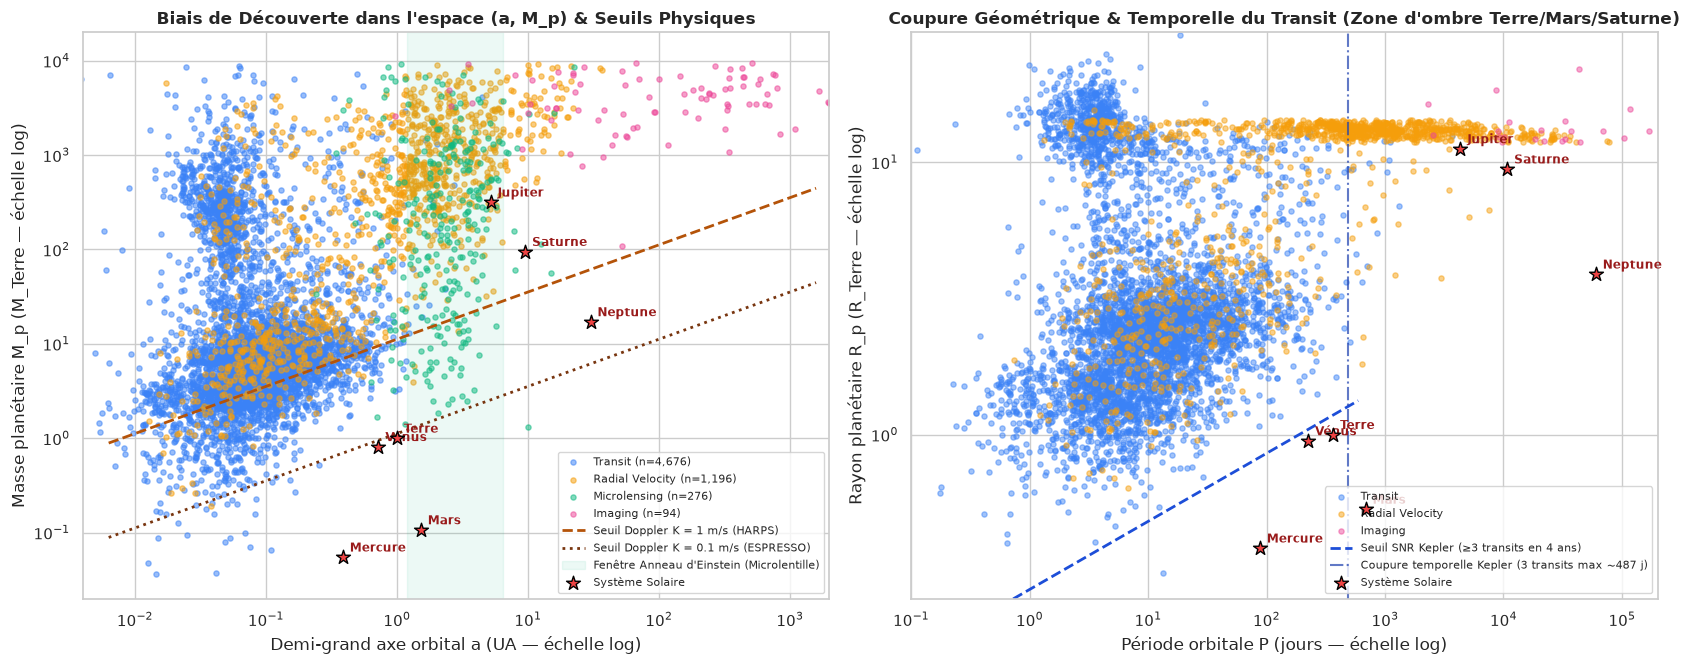

In [4]:
# Planètes du Système Solaire pour démontrer visuellement la zone d'ombre instrumentale
solar_system = pd.DataFrame([
    {"name": "Mercure", "a_au": 0.387, "period_d": 87.97, "mass_e": 0.055, "rad_e": 0.383},
    {"name": "Vénus",   "a_au": 0.723, "period_d": 224.70, "mass_e": 0.815, "rad_e": 0.949},
    {"name": "Terre",   "a_au": 1.000, "period_d": 365.25, "mass_e": 1.000, "rad_e": 1.000},
    {"name": "Mars",    "a_au": 1.524, "period_d": 686.98, "mass_e": 0.107, "rad_e": 0.532},
    {"name": "Jupiter", "a_au": 5.203, "period_d": 4332.6, "mass_e": 317.83, "rad_e": 11.209},
    {"name": "Saturne", "a_au": 9.537, "period_d": 10759.2, "mass_e": 95.16, "rad_e": 9.449},
    {"name": "Neptune", "a_au": 30.07, "period_d": 60190.0, "mass_e": 17.15, "rad_e": 3.883},
])

top_methods = ["Transit", "Radial Velocity", "Microlensing", "Imaging"]
palette_m = {
    "Transit": "#3b82f6",
    "Radial Velocity": "#f59e0b",
    "Microlensing": "#10b981",
    "Imaging": "#ec4899",
}
sub_bias = eda_pd[eda_pd["discovery_method"].isin(top_methods)].copy()

fig, axes = plt.subplots(1, 2, figsize=(17, 6.8))

# --- GRAPHIQUE GAUCHE : Demi-grand axe (UA) vs Masse (M_Terre) + Limites Doppler & Imagerie ---
for m in top_methods:
    d_m = sub_bias[(sub_bias["discovery_method"] == m) & (sub_bias["semi_major_axis_au_best"] > 0) & (sub_bias["mass_earth_est"] > 0)]
    axes[0].scatter(d_m["semi_major_axis_au_best"], d_m["mass_earth_est"], s=14, alpha=0.52, color=palette_m[m], label=f"{m} (n={len(d_m):,})")

# Courbes limites théoriques Vitesse Radiale : M_e_min(a) = (K / 28.4) * 317.83 * sqrt(a) pour étoile 1 M_sun
a_grid = np.logspace(-2.2, 3.2, 300)
m_rv_1ms = (1.0 / 28.4) * 317.83 * np.sqrt(a_grid)
m_rv_01ms = (0.10 / 28.4) * 317.83 * np.sqrt(a_grid)
axes[0].plot(a_grid, m_rv_1ms, "--", color="#b45309", lw=2, label="Seuil Doppler K = 1 m/s (HARPS)")
axes[0].plot(a_grid, m_rv_01ms, ":", color="#78350f", lw=2, label="Seuil Doppler K = 0.1 m/s (ESPRESSO)")
axes[0].axvspan(1.2, 6.5, color="#10b981", alpha=0.08, label="Fenêtre Anneau d'Einstein (Microlentille)")

# Système solaire
axes[0].scatter(solar_system["a_au"], solar_system["mass_e"], s=110, color="#ef4444", edgecolor="black", zorder=10, marker="*", label="Système Solaire")
for _, row in solar_system.iterrows():
    axes[0].annotate(row["name"], (row["a_au"], row["mass_e"]), xytext=(5, 4), textcoords="offset points", fontsize=8.5, fontweight="bold", color="#991b1b")

axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlim(4e-3, 2e3)
axes[0].set_ylim(2e-2, 2e4)
axes[0].set_xlabel("Demi-grand axe orbital a (UA — échelle log)")
axes[0].set_ylabel("Masse planétaire M_p (M_Terre — échelle log)")
axes[0].set_title("Biais de Découverte dans l'espace (a, M_p) & Seuils Physiques", fontweight="bold")
axes[0].legend(loc="lower right", fontsize=8)

# --- GRAPHIQUE DROITE : Période (jours) vs Rayon (R_Terre) + Seuil Photométrique Transit & Probabilité Géométrique ---
for m in ["Transit", "Radial Velocity", "Imaging"]:
    d_m = sub_bias[(sub_bias["discovery_method"] == m) & (sub_bias["orbital_period_days"] > 0) & (sub_bias["radius_earth_est"] > 0)]
    axes[1].scatter(d_m["orbital_period_days"], d_m["radius_earth_est"], s=14, alpha=0.48, color=palette_m[m], label=m)

p_grid = np.logspace(-1, 5.2, 300)
# Seuil SNR Transit : sur mission de durée T_obs = 4 ans (Kepler), SNR ∝ (R_p/R_sun)^2 * sqrt(T_obs / P) -> R_min ∝ P^(1/4)
r_kepler_limit = 0.48 * np.power(p_grid / 10.0, 0.25)
axes[1].plot(p_grid[p_grid <= 600], r_kepler_limit[p_grid <= 600], "--", color="#1d4ed8", lw=2, label="Seuil SNR Kepler (≥3 transits en 4 ans)")
axes[1].axvline(365.25 * 4 / 3, color="#1e40af", linestyle="-.", alpha=0.7, label="Coupure temporelle Kepler (3 transits max ~487 j)")

axes[1].scatter(solar_system["period_d"], solar_system["rad_e"], s=110, color="#ef4444", edgecolor="black", zorder=10, marker="*", label="Système Solaire")
for _, row in solar_system.iterrows():
    axes[1].annotate(row["name"], (row["period_d"], row["rad_e"]), xytext=(5, 4), textcoords="offset points", fontsize=8.5, fontweight="bold", color="#991b1b")

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlim(0.1, 2e5)
axes[1].set_ylim(0.25, 30)
axes[1].set_xlabel("Période orbitale P (jours — échelle log)")
axes[1].set_ylabel("Rayon planétaire R_p (R_Terre — échelle log)")
axes[1].set_title("Coupure Géométrique & Temporelle du Transit (Zone d'ombre Terre/Mars/Saturne)", fontweight="bold")
axes[1].legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()

**Enseignement majeur sur le biais de sélection :**
> Regardez où se situent **Mercure, Vénus, Mars, Saturne et Neptune** (étoiles rouges) : **presque tout notre Système Solaire interne et externe tombe sous les courbes de détection actuelles** (à droite de la coupure des 3 transits de Kepler à ~487 jours et sous le seuil Doppler de `1 m/s`) ! Seule **Jupiter** frôle le seuil des relevés Doppler de longue durée, et la **Terre** se trouve à l'extrême limite de sensibilité de Kepler. L'abondance apparente des *Jupiters chaudes* dans les années 1995–2008 puis des *Mini-Neptunes compactes* depuis Kepler reflète d'abord la fenêtre de visibilité géométrique ($P_{\text{geom}} = R_\star / a$) et énergétique de nos instruments.

---

## 4. Corrélations Multivariées (Pearson vs Spearman) & Réduction de Dimension ACP (PCA)

Confrontons maintenant les matrices **Pearson ($r$)** et **Spearman ($\rho$)** sur les variables physiques transformées en $\log_{10}$, puis projetons l'espace à 6 dimensions sur ses **2 composantes principales (ACP / PCA)**.

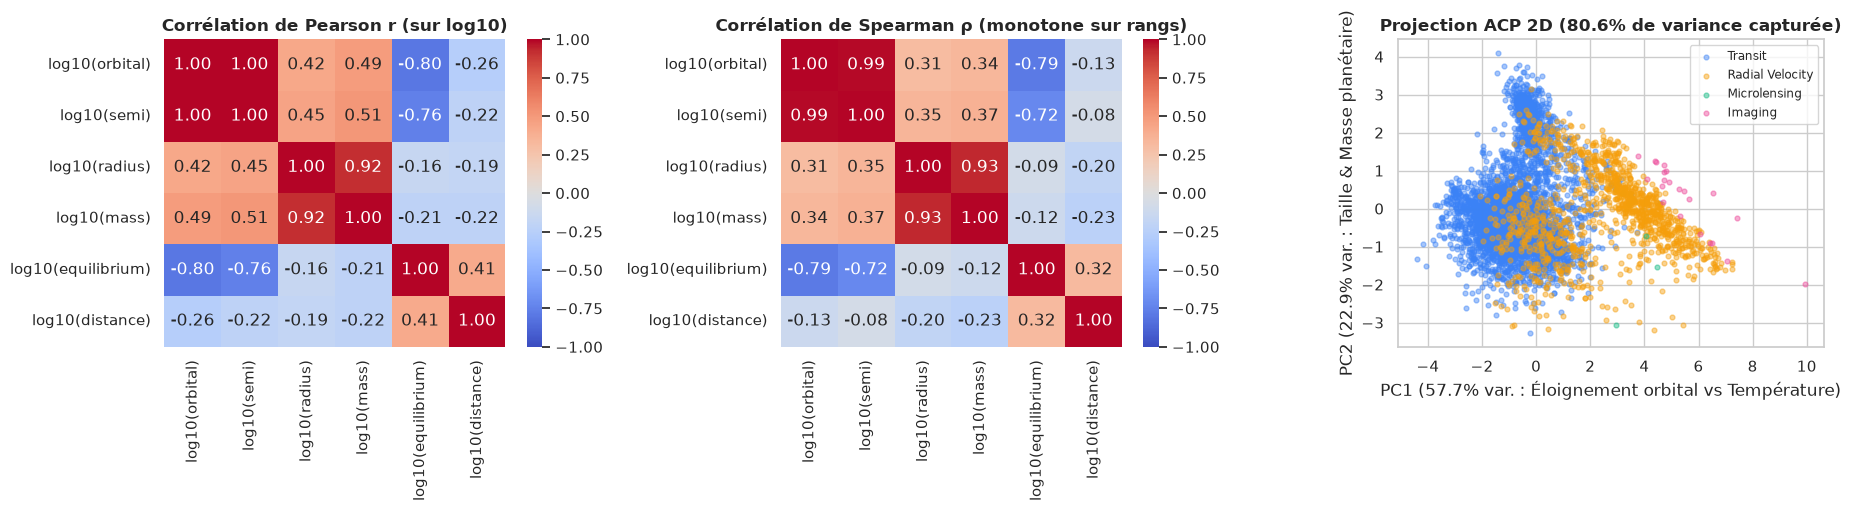

In [5]:
multiv_cols = [
    "orbital_period_days", "semi_major_axis_au_best", "radius_earth_est",
    "mass_earth_est", "equilibrium_temp_k_best", "distance_parsec",
]
mv_pd = eda_pd[multiv_cols + ["discovery_method"]].dropna().copy()
for c in multiv_cols:
    mv_pd = mv_pd[mv_pd[c] > 0]

log_mv = pd.DataFrame({f"log10({c.split('_')[0]})": np.log10(mv_pd[c]) for c in multiv_cols})

fig, axes = plt.subplots(1, 3, figsize=(18.5, 5.2))

sns.heatmap(log_mv.corr(method="pearson"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Corrélation de Pearson r (sur log10)", fontweight="bold")

sns.heatmap(log_mv.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Corrélation de Spearman ρ (monotone sur rangs)", fontweight="bold")

# ACP 2D standardisée
X_pca_in = StandardScaler().fit_transform(log_mv)
pca_eda = PCA(n_components=2, random_state=42)
coords_2d = pca_eda.fit_transform(X_pca_in)
var_exp = pca_eda.explained_variance_ratio_ * 100

for m, col in palette_m.items():
    mask = (mv_pd["discovery_method"] == m).values
    axes[2].scatter(coords_2d[mask, 0], coords_2d[mask, 1], s=12, alpha=0.45, color=col, label=m)
axes[2].set_xlabel(f"PC1 ({var_exp[0]:.1f}% var. : Éloignement orbital vs Température)")
axes[2].set_ylabel(f"PC2 ({var_exp[1]:.1f}% var. : Taille & Masse planétaire)")
axes[2].set_title(f"Projection ACP 2D ({var_exp.sum():.1f}% de variance capturée)", fontweight="bold")
axes[2].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

**Attention — Corrélation $\neq$ Causalité :**
> On observe une corrélation positive entre `distance_parsec` et `radius_earth_est` ($\rho > 0{,}30$). Est-ce que les planètes éloignées de la Terre sont physiquement plus grosses ? **Absolument pas !** C'est un **facteur de confusion instrumental** : plus une étoile est lointaine, plus son flux apparent diminue ($F \propto 1/d^2$), ce qui augmente le bruit de photons et empêche de détecter les petites planètes rocheuses !

---

## 5. Construction des Tables Analytiques Gold en Spark SQL (`/lakehouse/gold/exo_*`) & Compaction `OPTIMIZE`

Matérialisons nos analyses en **4 tables Delta Lake Gold** prêtes à alimenter le Dashboard Streamlit en quelques millisecondes :
1. **`/lakehouse/gold/exo_methods_bias`** : classement métier avec `DENSE_RANK()`, **courbe cumulée de Pareto** (`SUM(...) OVER (ORDER BY ...)`), médianes/IQR, probabilité géométrique moyenne de transit et taux d'incomplétude MAR par méthode.
2. **`/lakehouse/gold/exo_discovery_timeline`** : série annuelle (1992–2026) par méthode avec fonction de fenêtrage **`LAG()`** et cumul historique.
3. **`/lakehouse/gold/exo_candidates_summary`** : entonnoir comparatif des candidats et faux positifs **Kepler DR25 vs TESS TOI**.
4. **`/lakehouse/gold/exo_tess_lightcurves`** : sélection stratifiée via `ROW_NUMBER() OVER (PARTITION BY ...)` de **60 vraies courbes de lumière TESS** (`local_view` & `global_view`) pour l'exploration interactive des transits et binaires à éclipses dans Streamlit.

In [6]:
# 1. Table Gold #1 : Biais par méthode & Loi de Pareto
GOLD_METHODS_PATH = "/lakehouse/gold/exo_methods_bias"
df_gold_methods = spark.sql("""
    WITH base AS (
        SELECT discovery_method,
               COUNT(*) AS n_planets,
               ROUND(PERCENTILE_APPROX(orbital_period_days, 0.5), 2) AS median_period_days,
               ROUND(PERCENTILE_APPROX(orbital_period_days, 0.75) - PERCENTILE_APPROX(orbital_period_days, 0.25), 2) AS iqr_period_days,
               ROUND(PERCENTILE_APPROX(semi_major_axis_au_best, 0.5), 4) AS median_sma_au,
               ROUND(PERCENTILE_APPROX(radius_earth_est, 0.5), 2) AS median_radius_earth,
               ROUND(PERCENTILE_APPROX(mass_earth_est, 0.5), 2) AS median_mass_earth,
               ROUND(PERCENTILE_APPROX(distance_parsec, 0.5), 1) AS median_distance_pc,
               ROUND(100.0 * AVG(geometric_transit_prob), 2) AS avg_geom_transit_prob_pct,
               ROUND(100.0 * AVG(CASE WHEN discovery_locale = 'Space' THEN 1.0 ELSE 0.0 END), 1) AS pct_space_based,
               ROUND(100.0 * AVG(TRY_CAST(has_measured_radius AS DOUBLE)), 1) AS pct_measured_radius,
               ROUND(100.0 * AVG(TRY_CAST(has_measured_mass AS DOUBLE)), 1) AS pct_measured_mass,
               ROUND(100.0 * AVG(TRY_CAST(has_rv_amplitude AS DOUBLE)), 1) AS pct_measured_rv
        FROM v_exo_silver
        WHERE discovery_method IS NOT NULL
        GROUP BY discovery_method
    )
    SELECT discovery_method,
           n_planets,
           DENSE_RANK() OVER (ORDER BY n_planets DESC) AS rank_method,
           ROUND(100.0 * n_planets / SUM(n_planets) OVER (), 2) AS share_pct,
           ROUND(
               100.0 * SUM(n_planets) OVER (
                   ORDER BY n_planets DESC
                   ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
               ) / SUM(n_planets) OVER (),
               2
           ) AS pareto_cum_pct,
           median_period_days,
           iqr_period_days,
           median_sma_au,
           median_radius_earth,
           median_mass_earth,
           median_distance_pc,
           avg_geom_transit_prob_pct,
           pct_space_based,
           pct_measured_radius,
           pct_measured_mass,
           pct_measured_rv
    FROM base
    ORDER BY n_planets DESC
""")

df_gold_methods.coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_METHODS_PATH)
print(f"[GOLD OK] {GOLD_METHODS_PATH}")
df_gold_methods.show(12, truncate=False)

# 2. Table Gold #2 : Série temporelle 1992-2026 & Dynamique LAG()
GOLD_TIMELINE_PATH = "/lakehouse/gold/exo_discovery_timeline"
df_gold_timeline = spark.sql("""
    WITH yearly_method AS (
        SELECT TRY_CAST(discovery_year AS INT) AS discovery_year,
               discovery_method,
               COUNT(*) AS n_discovered,
               ROUND(PERCENTILE_APPROX(radius_earth_est, 0.5), 2) AS median_radius_earth,
               ROUND(PERCENTILE_APPROX(orbital_period_days, 0.5), 2) AS median_period_days
        FROM v_exo_silver
        WHERE discovery_year IS NOT NULL AND discovery_year >= 1992
        GROUP BY TRY_CAST(discovery_year AS INT), discovery_method
    )
    SELECT discovery_year,
           discovery_method,
           n_discovered,
           LAG(n_discovered, 1, 0) OVER (PARTITION BY discovery_method ORDER BY discovery_year) AS prev_year_discovered,
           n_discovered - LAG(n_discovered, 1, 0) OVER (PARTITION BY discovery_method ORDER BY discovery_year) AS yoy_change,
           SUM(n_discovered) OVER (
               PARTITION BY discovery_method
               ORDER BY discovery_year
               ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
           ) AS cumulative_discovered,
           median_radius_earth,
           median_period_days
    FROM yearly_method
    ORDER BY discovery_year, n_discovered DESC
""")
df_gold_timeline.coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_TIMELINE_PATH)
print(f"[GOLD OK] {GOLD_TIMELINE_PATH} ({df_gold_timeline.count()} lignes)")

# 3. Table Gold #3 : Entonnoir des candidats & faux positifs Kepler DR25 vs TESS
GOLD_CANDIDATES_PATH = "/lakehouse/gold/exo_candidates_summary"
df_gold_cand = spark.sql("""
    SELECT survey,
           disposition_group,
           COUNT(*) AS n_candidates,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY survey), 2) AS pct_within_survey,
           ROUND(PERCENTILE_APPROX(period_days, 0.5), 2) AS median_period_days,
           ROUND(PERCENTILE_APPROX(radius_earth, 0.5), 2) AS median_radius_earth,
           ROUND(PERCENTILE_APPROX(transit_depth_ppm, 0.5), 1) AS median_depth_ppm,
           ROUND(PERCENTILE_APPROX(snr, 0.5), 2) AS median_snr,
           ROUND(PERCENTILE_APPROX(snr, 0.75) - PERCENTILE_APPROX(snr, 0.25), 2) AS iqr_snr
    FROM v_exo_candidates
    GROUP BY survey, disposition_group
    ORDER BY survey, n_candidates DESC
""")
df_gold_cand.coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_CANDIDATES_PATH)
print(f"[GOLD OK] {GOLD_CANDIDATES_PATH}")
df_gold_cand.show(truncate=False)

# 4. Table Gold #4 : Échantillon stratifié de courbes de lumière TESS réelles (ROW_NUMBER OVER PARTITION BY)
GOLD_LC_PATH = "/lakehouse/gold/exo_tess_lightcurves"
bz_toi = spark.read.format("delta").load("/lakehouse/bronze/exo_tess_toi")
bz_toi.createOrReplaceTempView("v_bz_toi")

lc_sample_df = spark.sql("""
    WITH scored AS (
        SELECT toi AS toi_id,
               tic,
               CASE
                   WHEN secondary_depth > 0.25 * measured_depth_ppm AND measured_depth_ppm > 1500 THEN 'Suspect Binaire à Éclipses (Éclipse secondaire)'
                   WHEN catalog_depth_ppm >= 5000 THEN 'Transit Profond (Type Jupiter Chaude)'
                   WHEN catalog_depth_ppm BETWEEN 800 AND 4999 THEN 'Transit Intermédiaire (Type Neptune / Sous-Neptune)'
                   ELSE 'Transit Faible Profondeur (Type Super-Terre)'
               END AS transit_profile_type,
               ROUND(period_days, 4) AS period_days,
               ROUND(duration_days * 24.0, 2) AS duration_hours,
               ROUND(catalog_depth_ppm, 1) AS catalog_depth_ppm,
               ROUND(measured_depth_ppm, 1) AS measured_depth_ppm,
               ROUND(scatter_ppm, 1) AS scatter_ppm,
               ROUND(measured_depth_ppm / NULLIF(scatter_ppm, 0), 2) AS snr_estimate,
               ROUND(star_temperature_k, 0) AS star_temperature_k,
               ROUND(star_radius_sun, 2) AS star_radius_sun,
               ROUND(SQRT(GREATEST(catalog_depth_ppm, 0) * 1e-6) * COALESCE(star_radius_sun, 1.0) * 109.076, 2) AS est_radius_earth,
               ROUND(secondary_depth, 1) AS secondary_depth_ppm,
               local_view,
               global_view,
               ROW_NUMBER() OVER (
                   PARTITION BY CASE
                       WHEN secondary_depth > 0.25 * measured_depth_ppm AND measured_depth_ppm > 1500 THEN 'EB'
                       WHEN catalog_depth_ppm >= 5000 THEN 'HJ'
                       WHEN catalog_depth_ppm BETWEEN 800 AND 4999 THEN 'NP'
                       ELSE 'SE'
                   END
                   ORDER BY (measured_depth_ppm / NULLIF(scatter_ppm, 0)) DESC
               ) AS rn
        FROM v_bz_toi
        WHERE local_view IS NOT NULL AND global_view IS NOT NULL AND scatter_ppm > 0
    )
    SELECT * FROM scored WHERE rn <= 15
""").toPandas()

lc_sample_df["local_flux_json"] = lc_sample_df["local_view"].apply(lambda a: json.dumps([round(float(x), 5) for x in a]))
lc_sample_df["global_flux_json"] = lc_sample_df["global_view"].apply(lambda a: json.dumps([round(float(x), 5) for x in a]))
lc_clean_pd = lc_sample_df.drop(columns=["local_view", "global_view", "rn"])

spark.createDataFrame(lc_clean_pd).coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_LC_PATH)
print(f"[GOLD OK] {GOLD_LC_PATH} ({len(lc_clean_pd)} courbes de lumière TESS réelles enregistrées)")

# 5. Compaction OPTIMIZE de la table Silver pour prévenir le Small Files Problem sur le NameNode HDFS
print("\n=== COMPACTION DELTA OPTIMIZE SUR /lakehouse/silver/exo_planets ===")
spark.sql(f"OPTIMIZE delta.`{SILVER_PLANETS_PATH}`").show(truncate=False)

26/11/18 09:09:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:09:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:09:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:09:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:09:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:09:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 0

26/11/18 09:09:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:09:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:09:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:09:50 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


[GOLD OK] /lakehouse/gold/exo_methods_bias


26/11/18 09:09:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:09:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:09:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:09:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:09:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 09:09:52 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/18 0

+-----------------------------+---------+-----------+---------+--------------+------------------+---------------+-------------+-------------------+-----------------+------------------+-------------------------+---------------+-------------------+-----------------+---------------+
|discovery_method             |n_planets|rank_method|share_pct|pareto_cum_pct|median_period_days|iqr_period_days|median_sma_au|median_radius_earth|median_mass_earth|median_distance_pc|avg_geom_transit_prob_pct|pct_space_based|pct_measured_radius|pct_measured_mass|pct_measured_rv|
+-----------------------------+---------+-----------+---------+--------------+------------------+---------------+-------------+-------------------+-----------------+------------------+-------------------------+---------------+-------------------+-----------------+---------------+
|Transit                      |4676     |1          |73.80    |73.80         |8.01              |15.01          |0.0752       |2.45               |6.99      

[GOLD OK] /lakehouse/gold/exo_discovery_timeline (141 lignes)


[GOLD OK] /lakehouse/gold/exo_candidates_summary


+-----------+-----------------+------------+-----------------+------------------+-------------------+----------------+----------+-------+
|survey     |disposition_group|n_candidates|pct_within_survey|median_period_days|median_radius_earth|median_depth_ppm|median_snr|iqr_snr|
+-----------+-----------------+------------+-----------------+------------------+-------------------+----------------+----------+-------+
|Kepler DR25|FALSE POSITIVE   |4839        |50.60            |5.24              |8.96               |575.9           |34.2      |281.8  |
|Kepler DR25|CONFIRMED        |2748        |28.73            |11.35             |2.16               |448.6           |28.6      |32.3   |
|Kepler DR25|CANDIDATE        |1977        |20.67            |20.02             |1.74               |241.7           |11.0      |6.3    |
|TESS TOI   |CANDIDATE        |3871        |100.00           |4.38              |11.84              |5400.0          |1.08      |1.34   |
+-----------+-----------------+---

[GOLD OK] /lakehouse/gold/exo_tess_lightcurves (50 courbes de lumière TESS réelles enregistrées)

=== COMPACTION DELTA OPTIMIZE SUR /lakehouse/silver/exo_planets ===


+-------------------------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|path                                             |metrics                                                                                                                                                                       |
+-------------------------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|hdfs://namenode:9000/lakehouse/silver/exo_planets|{1, 2, {1494739, 1494739, 1494739.0, 1, 1494739}, {671301, 933337, 802319.0, 2, 1604638}, 1, NULL, NULL, 1, 1, 2, 0, false, 0, 0, 1794992998539, 0, 32, 0, NULL, NULL, 88, 32}|
+-------------------------------------------------+-----------------------------------------